Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


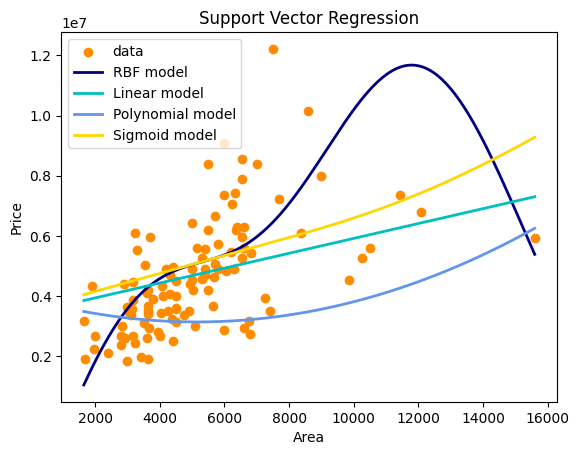

Linear MSE 1146287996325.3572 R2 0.6752247600322347
Poly MSE 1837094469801.1096 R2 0.47950009143796235
RBF MSE 5287437231566.012 R2 -0.4980778837440929
Sigmoid MSE 15494884554953.693 R2 -3.390131333260114


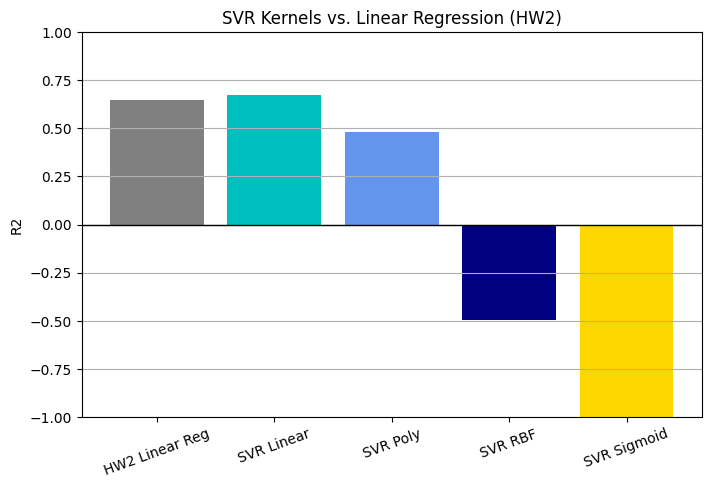

In [2]:
import numpy as np
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt
from IPython.display import display

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Machine Learning/Housing.csv'
housing = pd.DataFrame(pd.read_csv(file_path))

varlist =  ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

housing[varlist] = housing[varlist].apply(binary_map)

from sklearn.model_selection import train_test_split
np.random.seed(0)
housing_training, housing_validation = train_test_split(housing, train_size = 0.8, test_size = 0.2, random_state = 100)

features = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
            'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea']

X_train = housing_training[features].values
X_test  = housing_validation[features].values
Y_train = housing_training['price'].values
Y_test  = housing_validation['price'].values

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

Y_scaler = StandardScaler()
Y_train_s = Y_scaler.fit_transform(Y_train.reshape(-1, 1)).ravel()

from sklearn.svm import SVR

svr_rbf = SVR(kernel='rbf', C=1e3, gamma=0.1)
svr_lin = SVR(kernel='linear', C=1e3)
svr_poly = SVR(kernel='poly', C=1e3, degree=2)
svr_sigmoid = SVR(kernel='sigmoid')

y_rbf = svr_rbf.fit(X_train, Y_train_s).predict(X_test)
y_lin = svr_lin.fit(X_train, Y_train_s).predict(X_test)
y_poly = svr_poly.fit(X_train, Y_train_s).predict(X_test)
y_sigmoid = svr_sigmoid.fit(X_train, Y_train_s).predict(X_test)

y_rbf  = Y_scaler.inverse_transform(y_rbf.reshape(-1, 1)).ravel()
y_lin  = Y_scaler.inverse_transform(y_lin.reshape(-1, 1)).ravel()
y_poly = Y_scaler.inverse_transform(y_poly.reshape(-1, 1)).ravel()
y_sigmoid = Y_scaler.inverse_transform(y_sigmoid.reshape(-1, 1)).ravel()

area_grid = np.linspace(X_test[:, 0].min(), X_test[:, 0].max(), 200)
X_grid = np.zeros((200, 11))
X_grid[:, 0] = area_grid
area_real = scaler.mean_[0] + area_grid * scaler.scale_[0]

def pred(m):
    return Y_scaler.inverse_transform(m.predict(X_grid).reshape(-1, 1)).ravel()

plt.scatter(housing_validation['area'], Y_test, color='darkorange', label='data')
plt.plot(area_real, pred(svr_rbf), color='navy', lw=2, label='RBF model')
plt.plot(area_real, pred(svr_lin), color='c', lw=2, label='Linear model')
plt.plot(area_real, pred(svr_poly), color='cornflowerblue', lw=2, label='Polynomial model')
plt.plot(area_real, pred(svr_sigmoid), color='gold', lw=2, label='Sigmoid model')
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Support Vector Regression')
plt.legend()
plt.show()

from sklearn import metrics
models = [('Linear', y_lin), ('Poly', y_poly), ('RBF', y_rbf), ('Sigmoid', y_sigmoid)]
for name, p in models:
    print(name, "MSE", metrics.mean_squared_error(Y_test, p), "R2", metrics.r2_score(Y_test, p))


hw2_mse = 1249838484808.471
hw2_r2  = 0.6458860294045985

names = ['HW2 Linear Reg', 'SVR Linear', 'SVR Poly', 'SVR RBF', 'SVR Sigmoid']
r2  = [hw2_r2] + [metrics.r2_score(Y_test, p) for p in [y_lin, y_poly, y_rbf, y_sigmoid]]

plt.figure(figsize=(8, 5))
plt.bar(names, r2, color=['gray', 'c', 'cornflowerblue', 'navy', 'gold'])
plt.axhline(0, color='black', lw=1)
plt.ylabel('R2')
plt.title('SVR Kernels vs. Linear Regression (HW2)')
plt.xticks(rotation=20)
plt.grid(axis='y')
plt.ylim(-1, 1)
plt.show()